In [1]:
import cv2
import os
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import numpy as np
from PIL import Image

In [10]:
image_dir = 'activations/five/8'
image_files = os.listdir(image_dir)

image_files = [os.path.join(image_dir, f) for f in image_files if f.endswith('.png')]

images = []

In [11]:
for img_file in image_files:
    img = Image.open(img_file)
    img = np.array(img)
    images.append(img)

In [12]:
images_array = np.array(images)
print(f"Loaded {images_array.shape[0]} images with shape {images_array.shape[1:]}")
n_samples = images_array.shape[0]
images_flat = images_array.reshape(n_samples, -1)
print(f"Flattened images to shape: {images_flat.shape}")
tsne = TSNE(n_components=2, random_state=42)
images_tsne = tsne.fit_transform(images_flat)
print(f"t-SNE result shape: {images_tsne.shape}")

Loaded 64 images with shape (28, 28)
Flattened images to shape: (64, 784)
t-SNE result shape: (64, 2)


In [16]:
# Normalize t-SNE coordinates to [0,1]x[0,1] range
def normalize_to_unit_square(coordinates):
    """
    Normalize coordinates to [0,1]x[0,1] range
    """
    x_min, x_max = coordinates[:, 0].min(), coordinates[:, 0].max()
    y_min, y_max = coordinates[:, 1].min(), coordinates[:, 1].max()
    
    normalized_coords = coordinates.copy()
    normalized_coords[:, 0] = (coordinates[:, 0] - x_min) / (x_max - x_min)
    normalized_coords[:, 1] = (coordinates[:, 1] - y_min) / (y_max - y_min)
    
    return normalized_coords

# Apply normalization
images_tsne_normalized = normalize_to_unit_square(images_tsne)
print(f"Original t-SNE range: X[{images_tsne[:, 0].min():.2f}, {images_tsne[:, 0].max():.2f}], Y[{images_tsne[:, 1].min():.2f}, {images_tsne[:, 1].max():.2f}]")
print(f"Normalized t-SNE range: X[{images_tsne_normalized[:, 0].min():.2f}, {images_tsne_normalized[:, 0].max():.2f}], Y[{images_tsne_normalized[:, 1].min():.2f}, {images_tsne_normalized[:, 1].max():.2f}]")

Original t-SNE range: X[-5.66, 5.29], Y[-3.77, 3.19]
Normalized t-SNE range: X[0.00, 1.00], Y[0.00, 1.00]


Cluster distribution: [ 8  8 16 12 12  8]


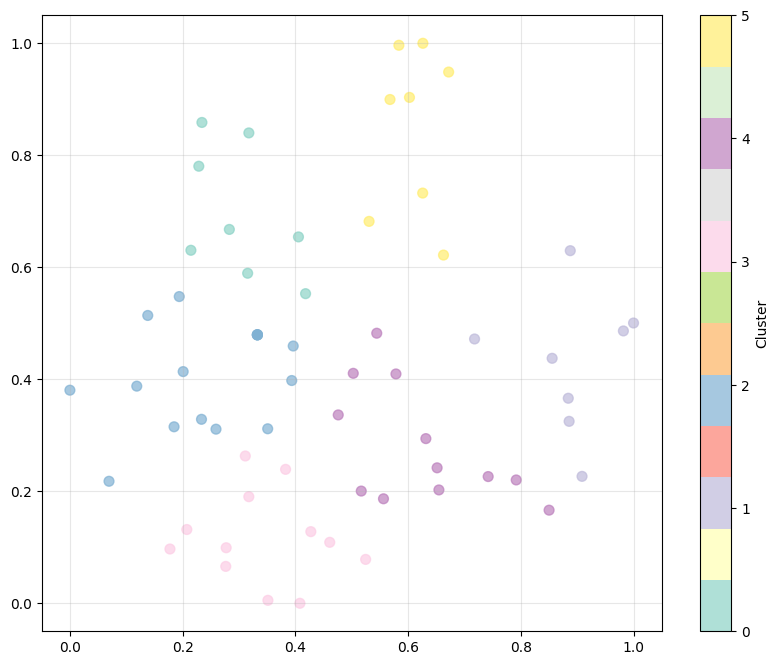

In [19]:
from sklearn.cluster import KMeans

n_clusters = 6
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
cluster_labels = kmeans.fit_predict(images_tsne_normalized)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(images_tsne_normalized[:, 0], images_tsne_normalized[:, 1], 
                     c=cluster_labels, cmap='Set3', alpha=0.7, s=50)
plt.grid(True, alpha=0.3)

plt.colorbar(scatter, label='Cluster')

cluster_counts = np.bincount(cluster_labels)
print(f"Cluster distribution: {cluster_counts}")

plt.show()